In [68]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, classification_report, roc_auc_score
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

import warnings
warnings.filterwarnings("ignore")

In [69]:
df = pd.read_csv(r"C:\Users\Shreyash shitole\Desktop\ibm customer churn data\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [70]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [71]:
df.tail(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [73]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [74]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [75]:
print(df.duplicated().sum())

0


In [76]:
for col in df.columns:
    print(col)
    print(df[col].unique())
    print("")

customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender
['Female' 'Male']

SeniorCitizen
[0 1]

Partner
['Yes' 'No']

Dependents
['No' 'Yes']

tenure
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]

PhoneService
['No' 'Yes']

MultipleLines
['No phone service' 'No' 'Yes']

InternetService
['DSL' 'Fiber optic' 'No']

OnlineSecurity
['No' 'Yes' 'No internet service']

OnlineBackup
['Yes' 'No' 'No internet service']

DeviceProtection
['No' 'Yes' 'No internet service']

TechSupport
['No' 'Yes' 'No internet service']

StreamingTV
['No' 'Yes' 'No internet service']

StreamingMovies
['No' 'Yes' 'No internet service']

Contract
['Month-to-month' 'One year' 'Two year']

PaperlessBilling
['Yes' 'No']

PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'

In [77]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [78]:
df["gender"].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [79]:
# Save Customer IDs
customer_ids = df["customerID"]

# Remove Customer ID from features
df.drop("customerID", axis=1, inplace=True)

In [80]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [81]:
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

In [82]:
df["Churn"] = df["Churn"].map({"Yes":1,"No":0})

In [83]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = le.fit_transform(df[col])

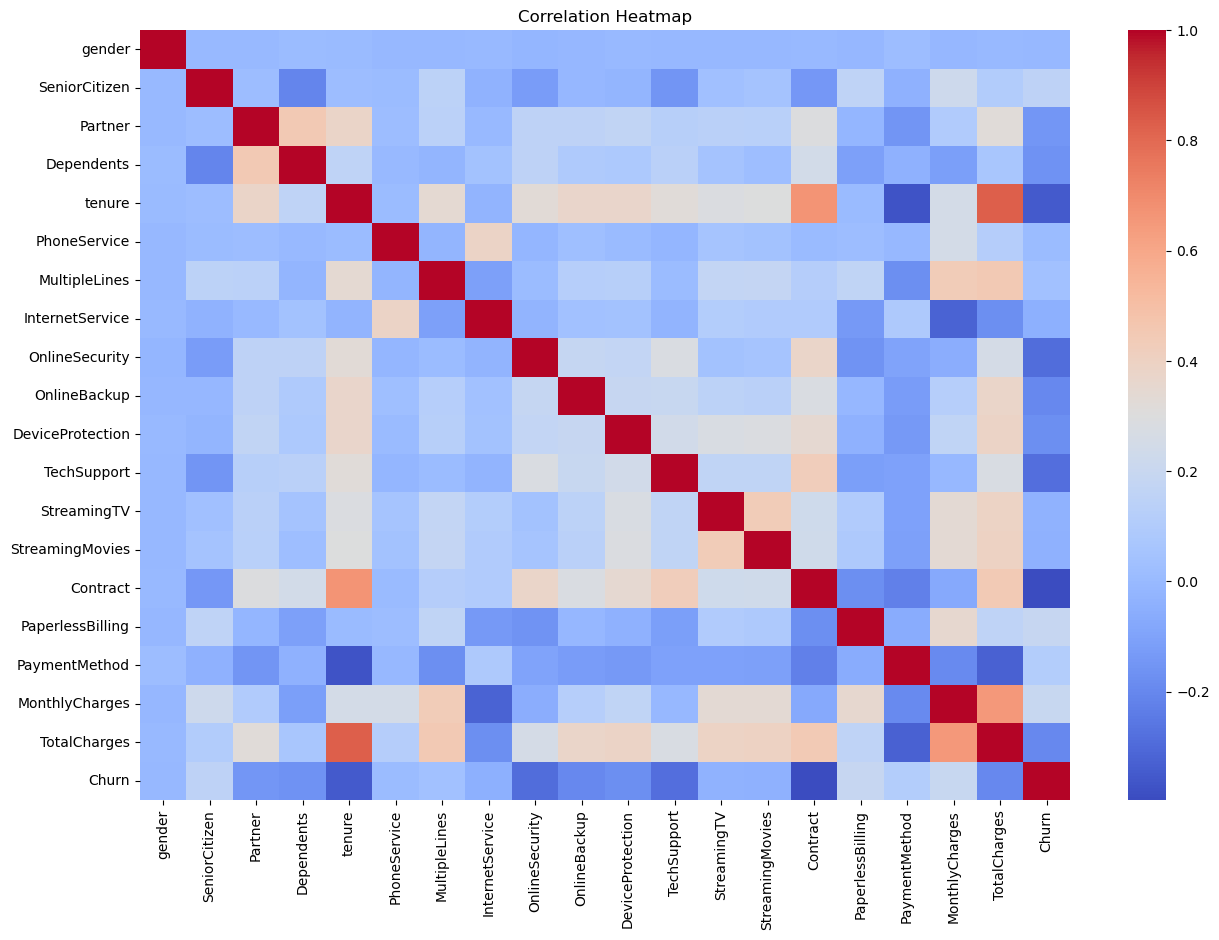

In [84]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

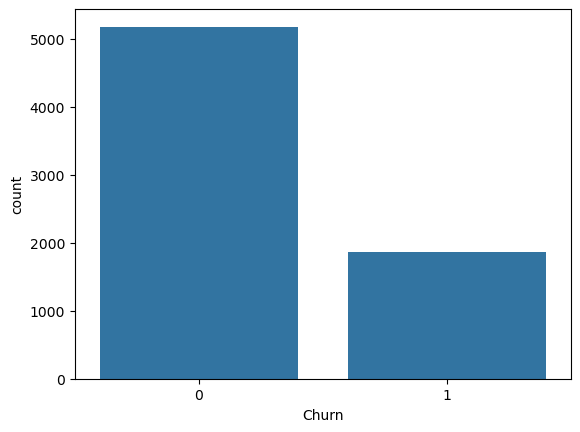

In [85]:
sns.countplot(x="Churn", data=df)
plt.show()

In [89]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [90]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [91]:
model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

In [92]:
print(y_pred)

[0 1 0 ... 0 0 0]


In [93]:
print("Accuracy :", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy : 0.7920511000709723

Confusion Matrix
[[928 107]
 [186 188]]

Classification Report
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [94]:
param_grid = {
    'n_estimators':[100,200,300],
    'max_depth':[5,10,15,None],
    'min_samples_split':[2,5],
    'min_samples_leaf':[1,2]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

best_model = grid.best_estimator_

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [95]:
y_pred = best_model.predict(X_test)

print("Accuracy After Tuning :", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

results = pd.DataFrame({
    "CustomerID": id_test.values,
    "Actual Churn": y_test.values,
    "Predicted Churn": y_pred
})

# Convert 0 and 1 back to Yes and No
results["Actual Churn"] = results["Actual Churn"].map({0: "No", 1: "Yes"})
results["Predicted Churn"] = results["Predicted Churn"].map({0: "No", 1: "Yes"})

print("\nCustomer-wise Churn Prediction")
print(results)

Accuracy After Tuning : 0.7963094393186657
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Customer-wise Churn Prediction
      CustomerID Actual Churn Predicted Churn
0     4376-KFVRS           No              No
1     2754-SDJRD           No             Yes
2     9917-KWRBE           No              No
3     0365-GXEZS           No              No
4     9385-NXKDA           No              No
...          ...          ...             ...
1404  5204-HMGYF           No              No
1405  9950-MTGYX           No              No
1406  3675-EQOZA           No              No
1407  3646-ITDGM           No              No
1408  3913-FCUUW           No              No

[1409 rows x 3 columns]


In [96]:
y_prob = best_model.predict_proba(X_test)[:,1]

fpr,tpr,threshold = roc_curve(y_test,y_prob)

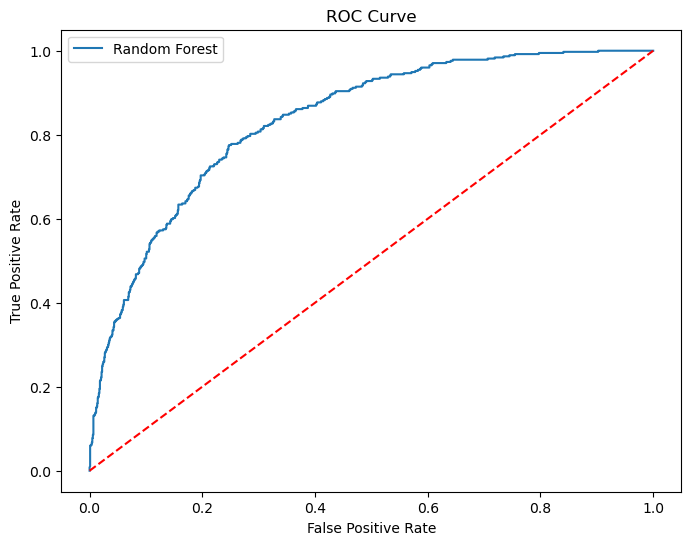

In [97]:
plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,label="Random Forest")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [98]:
print("ROC-AUC Score :", roc_auc_score(y_test,y_prob))

ROC-AUC Score : 0.8356764576713426


In [99]:
importance = pd.DataFrame({
    "Feature":X.columns,
    "Importance":best_model.feature_importances_
})

importance = importance.sort_values(by="Importance",ascending=False)


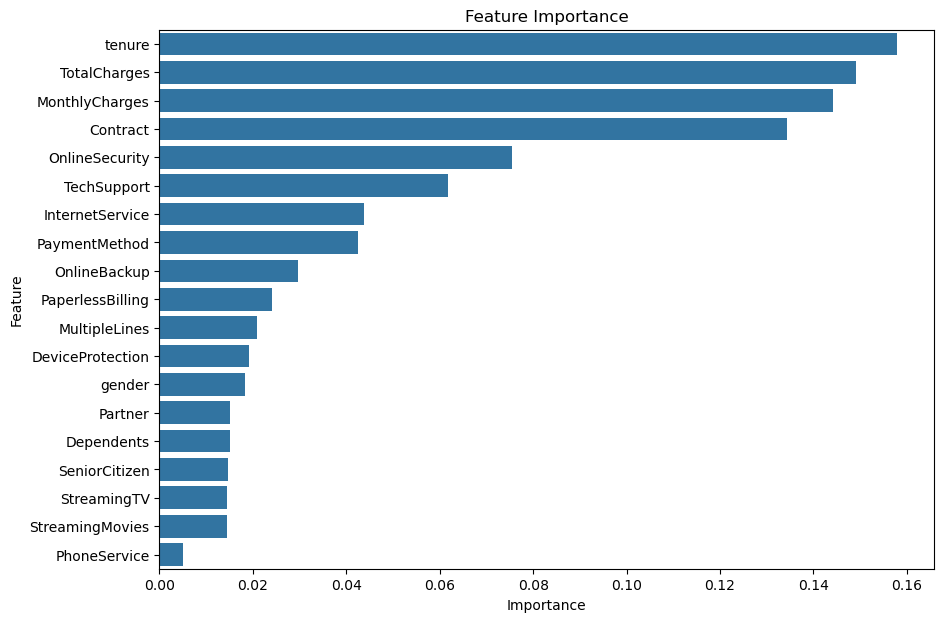

In [100]:
plt.figure(figsize=(10,7))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance")
plt.show()

In [101]:
print(importance)

             Feature  Importance
4             tenure    0.157985
18      TotalCharges    0.149177
17    MonthlyCharges    0.144273
14          Contract    0.134432
8     OnlineSecurity    0.075450
11       TechSupport    0.061793
7    InternetService    0.043712
16     PaymentMethod    0.042410
9       OnlineBackup    0.029601
15  PaperlessBilling    0.024071
6      MultipleLines    0.020793
10  DeviceProtection    0.019075
0             gender    0.018374
2            Partner    0.015125
3         Dependents    0.015112
1      SeniorCitizen    0.014669
12       StreamingTV    0.014542
13   StreamingMovies    0.014403
5       PhoneService    0.005003
